# Calculate annual, seasonal, and monthly mean of T, KPPHBL and Heat Flux

In [5]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))
import numpy as np
import xarray as xr
from MITgcmutils import mds
from src.utils import read_mitgcm
from src.utils import coarsen_UVWTS
path_scratch = '/scratch/jczhang/'
path_low = 'MITgcm_50km_withoutGM/verification/tutorial_reentrant_channel/run/'

# ds_fine = read_mitgcm.read_mitgrid_staggered(path_scratch + path_low)

start_iter = 2332800
delta_iter = 432
iters = np.arange(start_iter, start_iter + 360*delta_iter, delta_iter)

W_list = []

for it in iters:
    W = read_mitgcm._ocean_var(path_scratch + path_low, "W", it, ("k_l","j","i"))
    W_list.append(W)

# Stack into time series: (time, j, i)
W_all = xr.concat(W_list, dim="time").assign_coords(time=("time", iters))
# SAVE the full daily time series too
out_nc_all = "W_daily_low_noGM.nc"
W_all.name = "W"
W_all.to_netcdf(out_nc_all, engine="h5netcdf")
print("saved:", out_nc_all, "shape:", W_all.shape)
# Assign iteration index as coordinate
W_all = W_all.assign_coords(time=("time", iters))

# Now compute annual mean
W_annual = W_all.mean(dim="time")

out_nc = "W_annual_low_noGM.nc"
W_annual.name = "W"  # give it a variable name inside the file
W_annual.to_netcdf(out_nc, engine="h5netcdf")
print("saved:", out_nc)

saved: W_daily_low_noGM.nc shape: (360, 49, 120, 60)
saved: W_annual_low_noGM.nc


In [41]:
ds_T_FK = xr.open_dataset("./W_annual_low_FK.nc", engine="h5netcdf")
print(ds_T_FK)

<xarray.Dataset> Size: 3MB
Dimensions:  (k_l: 49, j: 120, i: 60)
Dimensions without coordinates: k_l, j, i
Data variables:
    W        (k_l, j, i) float64 3MB ...


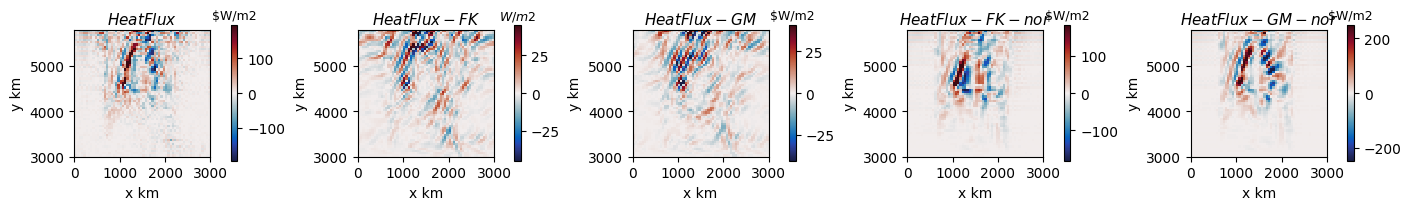

In [5]:
# High-resolution submesoscale heat flux
# ML_predicted submesoscale heat flux
# low-resolution submesoscale heat flux
# low resolution submesoscale heat flux with Fox Kemper parameterization

# path issue
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

# check the velocity field and vorticity field
import numpy as np
import xarray as xr
from src.utils import read_mitgcm
from src.utils import build_coarse_grid
from src.utils import wT_total
from src.utils import wT
from src.utils import make_grid
from src.utils import coarsen_UVWTS
from src.utils import mld_avg
import importlib
importlib.reload(wT_total)
importlib.reload(wT)
from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
import cmocean.cm as cmo
import h5netcdf

from MITgcmutils import mds
import matplotlib.pyplot as plt
# other parameters
path_scratch = '/scratch/jczhang/'
path_high = 'MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/'
path_low_FK = 'MITgcm_50km_FK/verification/tutorial_reentrant_channel/run/'
path_low = 'MITgcm_50km/verification/tutorial_reentrant_channel/run/'
# grid parameters
ds_fine = read_mitgcm.read_mitgrid_staggered(path_scratch + path_high)
ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds_fine,box_j=10, box_i=10)
grid = make_grid.make_grid_periodic_x(ds_coarse)
ds_50 = read_mitgcm.read_mitgrid_staggered(path_scratch + path_low)
# load the data
GM_diags_FK = mds.rdmds(path_scratch + path_low_FK + 'Diags/' +'GM_diags', 2488320)
GM_diags = mds.rdmds(path_scratch + path_low + 'Diags/' +'GM_diags', 2488320)
# kpphbl = xr.DataArray(diagMXL[1, :,:], dims = ("j","i"), name = "kpphbl")
psiX_FK = GM_diags_FK[0, ...]   # (k, j, i_g)  GM_PsiX
psiY_FK = GM_diags_FK[1, ...]   # (k, j_g, i)  GM_PsiY

psiX = GM_diags[0, ...]   # (k, j, i_g)  GM_PsiX
psiY = GM_diags[1, ...]   # (k, j_g, i)  GM_PsiY

# Wrap as DataArrays with correct dims/coords if you have them
psiX_FK = xr.DataArray(psiX_FK, dims=("k","j","i_g"))
psiY_FK = xr.DataArray(psiY_FK, dims=("k","j_g","i"))
PsiX = xr.DataArray(psiX, dims=("k","j","i_g"))
PsiY = xr.DataArray(psiY, dims=("k","j_g","i"))
# 
# 
dPsiY_dx_FK = (psiY_FK.roll(i=-1, roll_coords=False) - psiY_FK) / ds_50["DXG"]
dPsiX_dy_FK = (psiX_FK.shift(j=-1) - psiX_FK) / ds_50["DYG"]
dPsiY_dx = (PsiY.roll(i=-1, roll_coords=False) - PsiY) / ds_50["DXG"]
dPsiX_dy = (PsiX.shift(j=-1) - PsiX) / ds_50["DYG"]
# interp
grid = make_grid.make_grid_periodic_x(ds_50)
dPsiY_dx_c_FK = grid.interp(dPsiY_dx_FK, "Y", boundary="fill")
dPsiX_dy_c_FK = grid.interp(dPsiX_dy_FK, "X", boundary="periodic")
dPsiY_dx_c = grid.interp(dPsiY_dx, "Y", boundary="fill")
dPsiX_dy_c = grid.interp(dPsiX_dy, "X", boundary="periodic")
# 
Wstar_FK = (dPsiY_dx_c_FK - dPsiX_dy_c_FK)
Wstar = (dPsiY_dx_c - dPsiX_dy_c)
rho0, cp = 1035.0, 3994.0
#  temperature 
ds_T_FK = xr.open_dataset("./T_annual_low_FK.nc", engine="h5netcdf")
ds_T = xr.open_dataset("./T_annual_low.nc", engine="h5netcdf")
# 
w_annual_low_FK = xr.open_dataset("./W_annual_low_FK.nc", engine="h5netcdf")
w_annual_low_FK = grid.interp(w_annual_low_FK["W"], "Z", boundary="fill")
w_annual_low = xr.open_dataset("./W_annual_low.nc", engine="h5netcdf")
w_annual_low = grid.interp(w_annual_low["W"], "Z", boundary="fill")
# 
wT_annual_low_FK_nor = rho0 * cp * (w_annual_low_FK) * ds_T_FK["T"]
wT_annual_low_nor = rho0 * cp * (w_annual_low) * ds_T["T"]
# 
wT_annual_low_FK = rho0 * cp * (Wstar_FK ) * ds_T_FK["T"]
wT_annual_low = rho0 * cp * (Wstar) * ds_T["T"]
# 
ds_W_noGM = xr.open_dataset("./W_daily_low_noGM.nc", engine="h5netcdf")
W_noGM = grid.interp(ds_W_noGM["W"], "Z", to="center")  # (k,j,i)
ds_T_noGM = xr.open_dataset("./T_daily_low_noGM.nc", engine="h5netcdf")
wT_daily = ds_T_noGM["T"] * W_noGM
wT_annual_low_withoutGM = rho0 * cp * wT_daily.mean(dim="time")



def sym_limits(Z, q = 0.995):
    v = np.nanquantile(np.abs(Z), q)
    return float(v)

def pos_limits(Z, q=0.995):
    v = np.nanquantile(Z, q)
    return float(v)

def range_limits(Z, q = 0.995):
    """Return (vmin, vmax) from lower/upper quantiles."""
    vmin = np.nanquantile(Z, 1 - q)   # e.g. 0.5% if q=0.995
    vmax = np.nanquantile(Z, q)       # e.g. 99.5%
    return float(vmin), float(vmax)

# plot 
XC = ds_50["XC"][60:116,:]
YC = ds_50["YC"][60:116,:]
k = 12
fields = {
    r"$HeatFlux$":         {"Z": wT_annual_low_withoutGM[k,60:116,:],  "units": r"$W/m2",  "kind": "signed", "cmap": cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
    r"$HeatFlux-FK$":         {"Z": wT_annual_low_FK[k,60:116,:],  "units": r"$W/m2$",  "kind": "signed", "cmap": cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
    r"$HeatFlux-GM$":         {"Z": wT_annual_low[k,60:116,:],  "units": r"$W/m2",  "kind": "signed", "cmap": cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
    r"$HeatFlux-FK-nor$":         {"Z": wT_annual_low_FK_nor[k,60:116,:],  "units": r"$W/m2",  "kind": "signed", "cmap": cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
    r"$HeatFlux-GM-nor$":         {"Z": wT_annual_low_nor[k,60:116,:],  "units": r"$W/m2",  "kind": "signed", "cmap": cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
}     


# Compute norms/limits per field
for key, meta in fields.items():   
    Z = meta["Z"]
    if meta["kind"] == "signed":
        q = sym_limits(Z)
        meta["norm"] = TwoSlopeNorm(vcenter=0.0, vmin=-q, vmax=+q)
    elif meta["kind"] == "positive":
        vmin, vmax = range_limits(Z)
        meta["norm"] = Normalize(vmin=vmin, vmax=vmax)
    elif meta["kind"] == "seq":
        meta["norm"] = Normalize(vmin=np.nanmin(Z), vmax=np.nanmax(Z))
    else:
        meta["norm"] = None
vmin, vmax = range_limits(wT_annual_low_FK[k,60:116,:], q=1)  # <-- your function
shared_norm = Normalize(vmin=vmin, vmax=vmax)

# Plot: 2×5
fig, axes = plt.subplots(1,5, figsize=(14, 2), constrained_layout=True)
# --- dynamic number of panels ---
n_fields = len(fields)
# if only one panel
if n_fields == 1:
    axes = np.array([axes])
axes = axes.ravel()

for ax, (title, meta) in zip(axes, fields.items()):
    Z = meta["Z"]
    cmap = meta["cmap"]
    norm = meta["norm"]
    # norm = shared_norm
    XX = meta["XC"]
    YY = meta["YC"]
    pc = ax.pcolormesh(XX[:, :], YY[:, :], Z[:, :], shading='auto', cmap=cmap, norm=norm)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title, fontsize=11, pad=4)
    ax.set_xlabel('x km'); ax.set_ylabel('y km')
    cb = fig.colorbar(pc, ax=ax, pad=0.02)
    cb.ax.set_title(meta["units"], pad=4, fontsize=9)
fig.savefig("./heatflux_annual_k1.png")
plt.show()

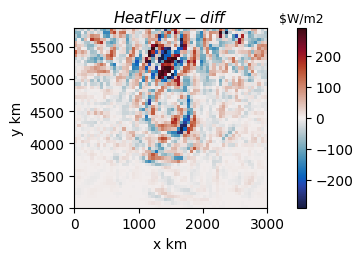

In [17]:
# High-resolution submesoscale heat flux
# ML_predicted submesoscale heat flux
# low-resolution submesoscale heat flux
# low resolution submesoscale heat flux with Fox Kemper parameterization

# path issue
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

# check the velocity field and vorticity field
import numpy as np
import xarray as xr
from src.utils import read_mitgcm
from src.utils import build_coarse_grid
from src.utils import wT_total
from src.utils import wT
from src.utils import make_grid
from src.utils import coarsen_UVWTS
from src.utils import mld_avg
import importlib
importlib.reload(wT_total)
importlib.reload(wT)
from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
import cmocean.cm as cmo
import h5netcdf

from MITgcmutils import mds
import matplotlib.pyplot as plt
# other parameters
path_scratch = '/scratch/jczhang/'
path_high = 'MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/'
path_low_FK = 'MITgcm_50km_FK/verification/tutorial_reentrant_channel/run/'
path_low = 'MITgcm_50km/verification/tutorial_reentrant_channel/run/'
# grid parameters
ds_fine = read_mitgcm.read_mitgrid_staggered(path_scratch + path_high)
ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds_fine,box_j=10, box_i=10)
grid = make_grid.make_grid_periodic_x(ds_coarse)
ds_50 = read_mitgcm.read_mitgrid_staggered(path_scratch + path_low)
# load the data
GM_diags_FK = mds.rdmds(path_scratch + path_low_FK + 'Diags/' +'GM_diags', 2488320)
GM_diags = mds.rdmds(path_scratch + path_low + 'Diags/' +'GM_diags', 2488320)
# kpphbl = xr.DataArray(diagMXL[1, :,:], dims = ("j","i"), name = "kpphbl")
psiX_FK = GM_diags_FK[0, ...]   # (k, j, i_g)  GM_PsiX
psiY_FK = GM_diags_FK[1, ...]   # (k, j_g, i)  GM_PsiY

psiX = GM_diags[0, ...]   # (k, j, i_g)  GM_PsiX
psiY = GM_diags[1, ...]   # (k, j_g, i)  GM_PsiY

# Wrap as DataArrays with correct dims/coords if you have them
psiX_FK = xr.DataArray(psiX_FK, dims=("k","j","i_g"))
psiY_FK = xr.DataArray(psiY_FK, dims=("k","j_g","i"))
PsiX = xr.DataArray(psiX, dims=("k","j","i_g"))
PsiY = xr.DataArray(psiY, dims=("k","j_g","i"))
# 
# 
dPsiY_dx_FK = (psiY_FK.roll(i=-1, roll_coords=False) - psiY_FK) / ds_50["DXG"]
dPsiX_dy_FK = (psiX_FK.shift(j=-1) - psiX_FK) / ds_50["DYG"]
dPsiY_dx = (PsiY.roll(i=-1, roll_coords=False) - PsiY) / ds_50["DXG"]
dPsiX_dy = (PsiX.shift(j=-1) - PsiX) / ds_50["DYG"]
# interp
grid = make_grid.make_grid_periodic_x(ds_50)
dPsiY_dx_c_FK = grid.interp(dPsiY_dx_FK, "Y", boundary="fill")
dPsiX_dy_c_FK = grid.interp(dPsiX_dy_FK, "X", boundary="periodic")
dPsiY_dx_c = grid.interp(dPsiY_dx, "Y", boundary="fill")
dPsiX_dy_c = grid.interp(dPsiX_dy, "X", boundary="periodic")
# 
Wstar_FK = (dPsiY_dx_c_FK - dPsiX_dy_c_FK)
Wstar = (dPsiY_dx_c - dPsiX_dy_c)
rho0, cp = 1035.0, 3994.0
#  temperature 
ds_T_FK = xr.open_dataset("./T_annual_low_FK.nc", engine="h5netcdf")
ds_T = xr.open_dataset("./T_annual_low.nc", engine="h5netcdf")
# 
w_annual_low_FK = xr.open_dataset("./W_annual_low_FK.nc", engine="h5netcdf")
w_annual_low_FK = grid.interp(w_annual_low_FK["W"], "Z", boundary="fill")
w_annual_low = xr.open_dataset("./W_annual_low.nc", engine="h5netcdf")
w_annual_low = grid.interp(w_annual_low["W"], "Z", boundary="fill")

# 
wT_annual_low_FK = rho0 * cp * (Wstar_FK ) * ds_T_FK["T"]
wT_annual_low = rho0 * cp * (Wstar) * ds_T["T"]
diff = wT_annual_low_FK - wT_annual_low



def sym_limits(Z, q = 0.995):
    v = np.nanquantile(np.abs(Z), q)
    return float(v)

def pos_limits(Z, q=0.995):
    v = np.nanquantile(Z, q)
    return float(v)

def range_limits(Z, q = 0.995):
    """Return (vmin, vmax) from lower/upper quantiles."""
    vmin = np.nanquantile(Z, 1 - q)   # e.g. 0.5% if q=0.995
    vmax = np.nanquantile(Z, q)       # e.g. 99.5%
    return float(vmin), float(vmax)

# plot 
XC = ds_50["XC"][60:116,:]
YC = ds_50["YC"][60:116,:]
k = 1
fields = {
    r"$HeatFlux-diff$":         {"Z": diff[k,60:116,:],  "units": r"$W/m2",  "kind": "signed", "cmap": cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
 
}     


# Compute norms/limits per field
for key, meta in fields.items():   
    Z = meta["Z"]
    if meta["kind"] == "signed":
        q = sym_limits(Z)
        meta["norm"] = TwoSlopeNorm(vcenter=0.0, vmin=-q, vmax=+q)
    elif meta["kind"] == "positive":
        vmin, vmax = range_limits(Z)
        meta["norm"] = Normalize(vmin=vmin, vmax=vmax)
    elif meta["kind"] == "seq":
        meta["norm"] = Normalize(vmin=np.nanmin(Z), vmax=np.nanmax(Z))
    else:
        meta["norm"] = None
vmin, vmax = range_limits(wT_annual_low_FK[k,60:116,:], q=1)  # <-- your function
shared_norm = Normalize(vmin=vmin, vmax=vmax)

# Plot: 2×5
fig, axes = plt.subplots(1,1, figsize=(7, 2.5), constrained_layout=True)
# --- dynamic number of panels ---
n_fields = len(fields)
# if only one panel
if n_fields == 1:
    axes = np.array([axes])
axes = axes.ravel()

for ax, (title, meta) in zip(axes, fields.items()):
    Z = meta["Z"]
    cmap = meta["cmap"]
    norm = meta["norm"]
    # norm = shared_norm
    XX = meta["XC"]
    YY = meta["YC"]
    pc = ax.pcolormesh(XX[:, :], YY[:, :], Z[:, :], shading='auto', cmap=cmap, norm=norm)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title, fontsize=11, pad=4)
    ax.set_xlabel('x km'); ax.set_ylabel('y km')
    cb = fig.colorbar(pc, ax=ax, pad=0.02)
    cb.ax.set_title(meta["units"], pad=4, fontsize=9)
fig.savefig("./heatflux_annual_diff.png")
plt.show()